# Calibration: recover prices before claiming identified parameters

This notebook executes a bounded, current-source synthetic call-calibration demonstration. It does not load a market surface or an old optimizer result. A small noisy surface lets us separate **optimizer termination**, **recovered prices**, **parameter values** and **numerical refinement**.

The contracts are explicitly American calls under the guarded no-early-exercise assumptions from [Notebook 01](01_pricing_and_exercise.ipynb). European transform evaluation follows that exact reduction; it is not a relabelling of arbitrary American observations.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/rvlab/pricing").is_dir())
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))
import rvlab
assert Path(rvlab.__file__).resolve().is_relative_to((ROOT / "src").resolve())
import numpy as np
import pandas as pd
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import public_notebook_support as demo
demo.style()
SEED = 42

Matplotlib is building the font cache; this may take a moment.


## 1. Declare generation, noise and fitting budgets

Each model generates its own synthetic 14/30/60-day call surface at six strikes per maturity. Four contracts per maturity train the fit and two are held out. Independent Gaussian price perturbations have standard deviation $.001 per unit, seed 42. Synthetic bid/ask half-spreads are $.025 and the positive spread floor remains $.005.

Generation uses finer Fourier/Riccati settings than fitting. BS has one free flat volatility; Heston has all five coefficients free; rough Heston has only `v0` free, with the remaining five fixed at the generating values. The maximum is 60 optimizer evaluations per model. These are demonstrations rather than a full multistart identification study.

In [2]:
from dataclasses import asdict
display(pd.DataFrame([{"role":"generate", **asdict(demo.FINE_FOURIER)},
    {"role":"fit", **asdict(demo.FOURIER)}]))

,role,quadrature_nodes,fourier_cutoff,riccati_steps
0,generate,192,200.0,512
1,fit,96,100.0,256


In [3]:
calibration = demo.synthetic_calibration(seed=SEED)
plt.close(calibration["figure"])
display(calibration["summary"])
display(calibration["failures"])

,model,free_parameters,optimizer_converged,numerically_stable,numerical_ready,...,active_bounds,train_price_rmse,heldout_clean_rmse,max_refinement_change,seconds
0,Black–Scholes,1,True,True,True,...,,0.000727,0.000107,0.00000,0.051985
1,Heston,5,True,True,True,...,,0.000575,0.000313,0.00004,0.043464
2,Rough Heston,1,True,True,True,...,,0.000484,0.000199,0.00012,1.014855


""


## 2. Inspect recovered prices and all fitted coefficients

The figure compares held-out fitted prices with the **clean generating prices**, rather than simply matching noisy training targets. A single BS inverse differs from fitting one flat volatility to many contracts. Full Heston recovery can remain weakly identified on short maturities; fixing rough coefficients makes its `v0` demonstration easier and supplies no evidence that all six rough coefficients are recoverable.

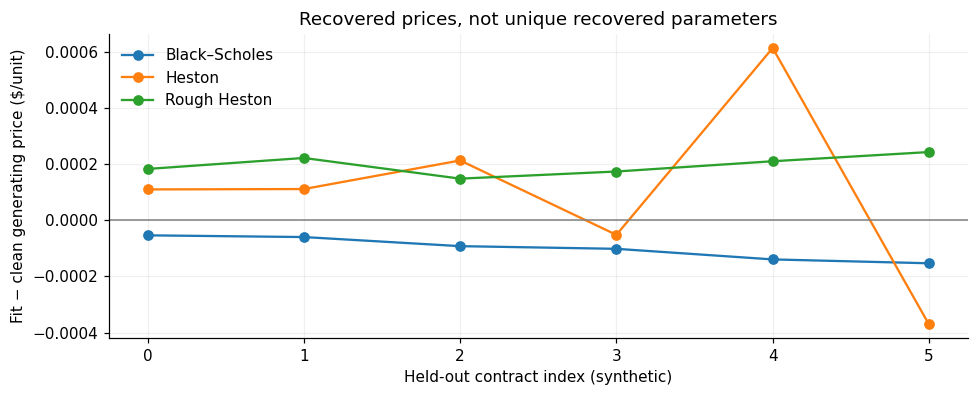

,model,parameter,generating,initial,fitted,fixed
0,Black–Scholes,volatility,0.200,0.300,0.199990,False
1,Heston,v0,0.040,0.035,0.039993,False
2,Heston,theta,0.045,0.050,0.046078,False
3,Heston,kappa,1.500,1.200,1.425665,False
4,Heston,vol_of_vol,0.300,0.250,0.312610,False
5,Heston,rho,-0.600,-0.450,-0.575139,False
6,Rough Heston,v0,0.040,0.030,0.040008,False
7,Rough Heston,theta,0.045,0.045,0.045000,True
8,Rough Heston,kappa,1.000,1.000,1.000000,True
9,Rough Heston,vol_of_vol,0.120,0.120,0.120000,True


In [4]:
display(calibration["figure"])
plt.close(calibration["figure"])
display(calibration["parameters"])

## 3. Optimizer convergence and numerical stability are separate

The call calibrator checks Fourier quadrature, multiple cutoffs, fractional-Riccati time resolution where relevant, and combined refinements. Each comparison must meet the unchanged price tolerance and 10% effective-half-spread budget. A stable converged fit can still fit the wrong model or fail to identify its parameters. A failed check remains a reported result, not an automatically relaxed tolerance.

In [5]:
if not calibration["refinement"].empty:
    display(calibration["refinement"][["model","check","status","max_price_change","price_stable","spread_stable"]])
else:
    display(Markdown("No completed fit supplied numerical checks; see the retained failure table."))

,model,check,status,max_price_change,price_stable,spread_stable
0,Black–Scholes,quadrature,stable,0.000000e+00,True,True
1,Black–Scholes,cutoff_mid,stable,0.000000e+00,True,True
2,Black–Scholes,cutoff_far,stable,0.000000e+00,True,True
3,Black–Scholes,cutoff_cumulative,stable,0.000000e+00,True,True
4,Black–Scholes,joint,stable,0.000000e+00,True,True
5,Heston,quadrature,stable,1.010303e-14,True,True
6,Heston,cutoff_mid,stable,4.013526e-05,True,True
7,Heston,cutoff_far,stable,3.823687e-08,True,True
8,Heston,cutoff_cumulative,stable,4.017350e-05,True,True
9,Heston,joint,stable,4.017350e-05,True,True


## 4. What this small run does not repeat

The earlier American Heston/mean-reversion-curve work used multiple starts, noise, spread weighting, grid investigations and longer maturity panels. Its conclusions included both unfinished optimizer termination and weak identification; a lower parameter bound was not automatically a numerical defect. The [curated research report](../reports/research_findings.md) preserves those conclusions without requiring the large private archive.

This fresh demonstration does not repeat that expensive campaign, prove parameter uniqueness, calibrate American puts under rough Heston, estimate a historical rough state or validate hedging. Full synthetic and real-data studies should declare their bounds, selection rule, independent observations and numerical budgets before execution.